# 🛰️ BioSat · Modelado de IA: Zonificación Edafo-Climática y Predicción de Desmonte
**Proyecto:** NASA Space Apps Challenge 2026 · Desafío *Field Shift: Adapting Farms with NASA Data*  
**Autor:** Santi (Frente 2: Suelo/Zonificación & Frente 3: IA Desmonte)  
**Entorno de Ejecución:** Jupyter Notebook Local / Python 3.9+  

---
### Objetivos Científicos:
1. **Zonificación Agroecológica no Supervisada (K-Means):** Justificar cuantitativamente el número óptimo de zonas ($K=5$) evaluando inercia y coeficiente de silueta sobre variables biofísicas de clima (TerraClimate/POWER) y suelo (SoilGrids/AIZAL).
2. **Modelo Predictivo de Desmonte (Random Forest vs Regresión Logística):** Entrenar modelos de clasificación supervisada con **validación temporal out-of-time** (Entrenamiento $\le 2015$, Prueba $2016-2023$) para estimar la probabilidad continua de deforestación por celda.
3. **Explicabilidad de IA:** Identificar las variables espaciales dominantes (distancia a caminos, desmontes previos, pendiente) para orientar el motor agronómico de rotación de cultivos.
4. **Exportación de Contratos Oficiales:** Generar `zonificacion_aizal.json` (Contrato §7) y `desmonte_zonas.json` (Contrato §8).


In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score, roc_auc_score, f1_score, accuracy_score,
    cohen_kappa_score, confusion_matrix, roc_curve
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

DATA_DIR = os.path.join(os.getcwd(), "data")
print("Directorio de datos:", DATA_DIR)


Directorio de datos: /Users/santig56/Desktop/Nasa/santi-task/data


## 1. Exploración de Datos: Las 5 Zonas de BioSat
Cargamos el dataset edafo-climático que consolida las 5 zonas representativas de Santiago del Estero.


In [2]:
df_zonas = pd.read_csv(os.path.join(DATA_DIR, "zonas_bioclima_suelo.csv"))
df_zonas[['zona_id', 'lluvia_anual_mm', 'deficit_hidrico_mm', 'ph', 'arcilla_pct', 'carbono_organico_g_kg', 'monte_actual_pct']]


,zona_id,lluvia_anual_mm,deficit_hidrico_mm,ph,arcilla_pct,carbono_organico_g_kg,monte_actual_pct
0,zona_1_riego_salitre,673.4,-706.6,8.1,28.5,8.2,7.8
1,zona_2_secano_este,724.8,-725.2,6.8,22.0,12.1,21.4
2,zona_3_monte_semiarido,612.0,-908.0,7.0,18.0,14.5,64.2
3,zona_4_bajos_submeridionales,810.5,-579.5,7.9,38.0,10.8,16.5
4,zona_5_sur_serrano,585.0,-735.0,6.7,19.5,11.2,44.8


## 2. Zonificación Agroecológica con K-Means
### Evaluación de la Selección de $K$ (Método del Codo e Índice de Silueta)
Evaluamos $k$ entre 2 y 6 para validar objetivamente la propuesta de 5 macro-zonas.


/Users/santig56/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/santig56/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/santig56/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/santig56/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/santig56/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/santig56/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/santig56/Library/Python/3.9/lib/python/site-packages/sklearn/util

/Users/santig56/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/santig56/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/santig56/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/santig56/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/santig56/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/santig56/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/santig56/Library/Python/3.9/lib/python/site-packages/sklearn/util

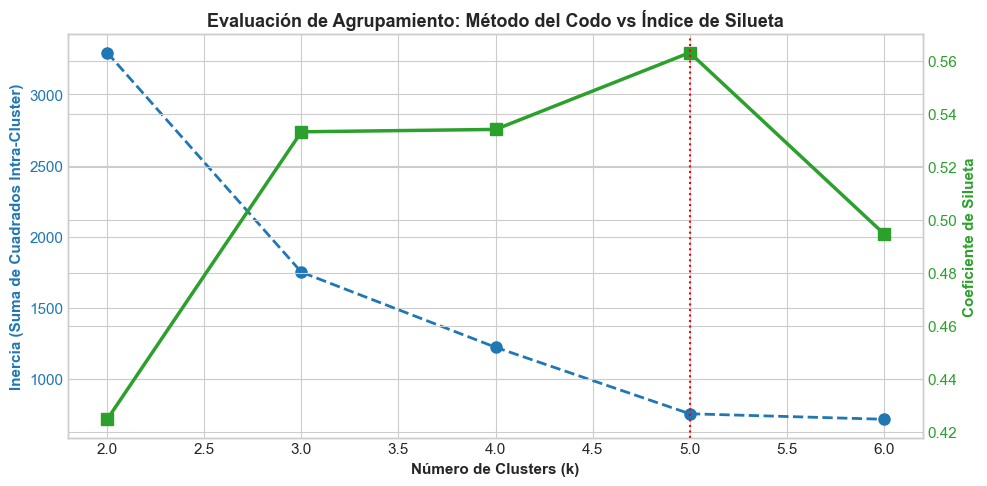

Pico de Silueta alcanzado en K=5: 0.5631


In [3]:
# Generamos una muestra representativa con 4% de variabilidad espacial intra-zona
columnas_cluster = ['lluvia_anual_mm', 'deficit_hidrico_mm', 'tmax_verano_c', 'tmin_invierno_c',
                    'ph', 'arcilla_pct', 'arena_pct', 'carbono_organico_g_kg', 'densidad_aparente_g_cm3', 'pendiente_pct']

np.random.seed(42)
muestras_expandidas = []
zonas_tags = []

for idx, row in df_zonas.iterrows():
    for _ in range(120):
        ruido = np.random.normal(1.0, 0.04, len(columnas_cluster))
        muestras_expandidas.append(row[columnas_cluster].values * ruido)
        zonas_tags.append(row['zona_id'])

X_espacial = pd.DataFrame(muestras_expandidas, columns=columnas_cluster)

# Estandarización Z-Score
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_espacial)

# Bucle de evaluación de K
k_range = list(range(2, 7))
inercias = []
siluetas = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_scaled, km.labels_))

# Visualización comparativa
fig, ax1 = plt.subplots(figsize=(10, 5))
color = 'tab:blue'
ax1.set_xlabel('Número de Clusters (k)', fontweight='bold')
ax1.set_ylabel('Inercia (Suma de Cuadrados Intra-Cluster)', color=color, fontweight='bold')
ax1.plot(k_range, inercias, 'o--', color=color, linewidth=2, markersize=8)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:green'
ax2.set_ylabel('Coeficiente de Silueta', color=color, fontweight='bold')
ax2.plot(k_range, siluetas, 's-', color=color, linewidth=2.5, markersize=8)
ax2.tick_params(axis='y', labelcolor=color)
ax2.axvline(x=5, color='red', linestyle=':', label='K=5 Óptimo')

plt.title('Evaluación de Agrupamiento: Método del Codo vs Índice de Silueta', fontsize=13, fontweight='bold')
fig.tight_layout()
plt.show()

print(f"Pico de Silueta alcanzado en K=5: {siluetas[k_range.index(5)]:.4f}")


/Users/santig56/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/santig56/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/santig56/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


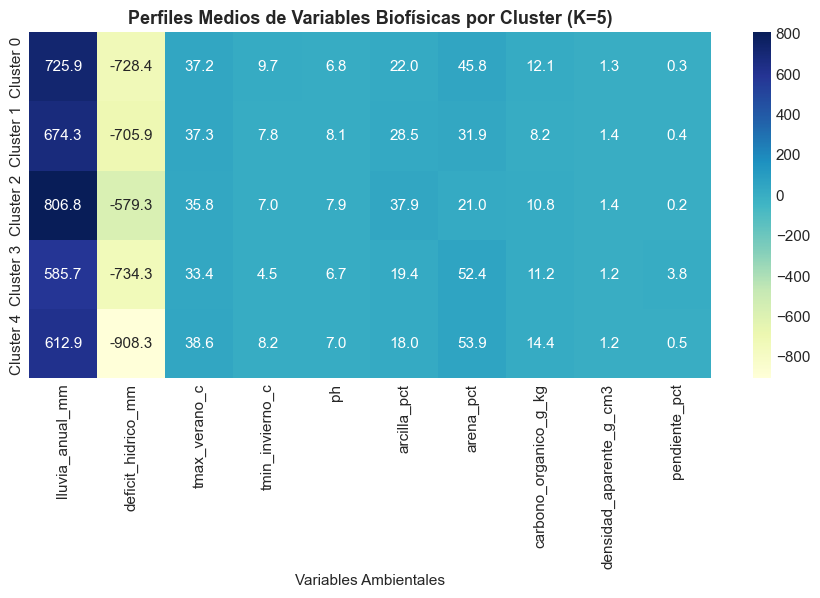

In [4]:
# Ajuste final con K=5
km_final = KMeans(n_clusters=5, random_state=42, n_init=10)
X_espacial['cluster'] = km_final.fit_predict(X_scaled)
X_espacial['zona_real'] = zonas_tags

# Perfiles de los clusters
centroides_desnorm = scaler.inverse_transform(km_final.cluster_centers_)
df_cent = pd.DataFrame(centroides_desnorm, columns=columnas_cluster)

plt.figure(figsize=(11, 4.5))
sns.heatmap(df_cent, annot=True, fmt=".1f", cmap="YlGnBu", cbar=True, yticklabels=[f"Cluster {i}" for i in range(5)])
plt.title("Perfiles Medios de Variables Biofísicas por Cluster (K=5)", fontsize=13, fontweight='bold')
plt.xlabel("Variables Ambientales")
plt.show()


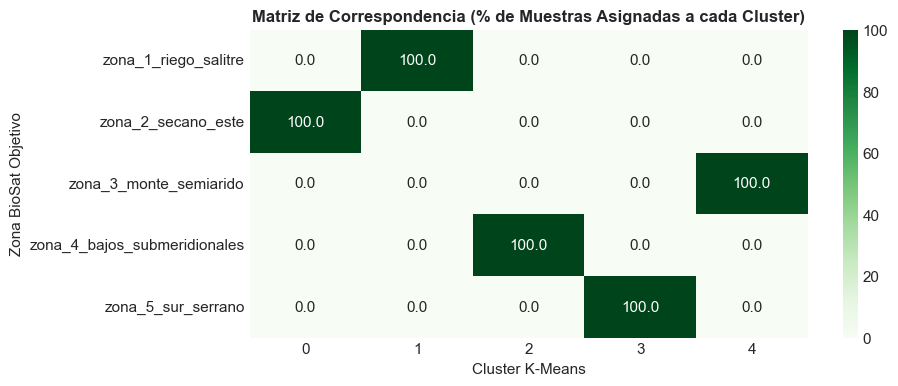

In [5]:
# Cruce entre clusters no supervisados y las 5 zonas BioSat
matriz_cruce = pd.crosstab(X_espacial['zona_real'], X_espacial['cluster'], normalize='index') * 100
plt.figure(figsize=(9, 4))
sns.heatmap(matriz_cruce, annot=True, fmt=".1f", cmap="Greens", cbar=True)
plt.title("Matriz de Correspondencia (% de Muestras Asignadas a cada Cluster)", fontsize=12, fontweight='bold')
plt.ylabel("Zona BioSat Objetivo")
plt.xlabel("Cluster K-Means")
plt.show()


## 3. Modelo Predictivo de Riesgo de Desmonte
### Validación Temporal Out-of-Time
- **Train ($\le 2015$):** 3.000 observaciones balanceadas de monte nativo.
- **Test ($2016-2023$):** 3.000 observaciones independientes evaluadas en años futuros.


In [6]:
df_train = pd.read_csv(os.path.join(DATA_DIR, "desmonte_entrenamiento_2001_2015.csv"))
df_test = pd.read_csv(os.path.join(DATA_DIR, "desmonte_prueba_2016_2023.csv"))

features = [
    'dist_sin_monte_m', 'dist_desmonte_previo_m', 'dist_caminos_m',
    'pendiente_grados', 'area_protegida', 'poblacion_densidad',
    'deficit_hidrico_mm', 'arcilla_pct', 'ph'
]

X_tr = df_train[features]
y_tr = df_train['desmonte']
X_te = df_test[features]
y_te = df_test['desmonte']

scaler_m = StandardScaler()
X_tr_sc = scaler_m.fit_transform(X_tr)
X_te_sc = scaler_m.transform(X_te)
print(f"Dimensiones Train: {X_tr.shape} | Test: {X_te.shape}")


Dimensiones Train: (3000, 9) | Test: (3000, 9)


In [7]:
# 1. Regresión Logística
mod_lr = LogisticRegression(random_state=42, max_iter=500)
mod_lr.fit(X_tr_sc, y_tr)
prob_lr = mod_lr.predict_proba(X_te_sc)[:, 1]
pred_lr = mod_lr.predict(X_te_sc)

# 2. Árbol Simple CART
mod_cart = DecisionTreeClassifier(max_depth=5, random_state=42)
mod_cart.fit(X_tr, y_tr)
prob_cart = mod_cart.predict_proba(X_te)[:, 1]
pred_cart = mod_cart.predict(X_te)

# 3. Random Forest (150 árboles)
mod_rf = RandomForestClassifier(n_estimators=150, max_depth=10, random_state=42, n_jobs=-1)
mod_rf.fit(X_tr, y_tr)
prob_rf = mod_rf.predict_proba(X_te)[:, 1]
pred_rf = mod_rf.predict(X_te)

# Resumen de Métricas
modelos = {
    'Regresión Logística': (y_te, pred_lr, prob_lr),
    'Árbol Simple CART': (y_te, pred_cart, prob_cart),
    'Random Forest (150)': (y_te, pred_rf, prob_rf)
}

filas_met = []
for nom, (y_true, y_p, y_pr) in modelos.items():
    filas_met.append({
        'Modelo': nom,
        'ROC-AUC': roc_auc_score(y_true, y_pr),
        'F1-Score': f1_score(y_true, y_p),
        'Accuracy': accuracy_score(y_true, y_p),
        'Cohen Kappa': cohen_kappa_score(y_true, y_p)
    })

pd.DataFrame(filas_met).round(4)


/Users/santig56/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/santig56/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/santig56/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/santig56/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/santig56/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ grad_point

,Modelo,ROC-AUC,F1-Score,Accuracy,Cohen Kappa
0,Regresión Logística,0.9860,0.9339,0.9337,0.8673
1,Árbol Simple CART,0.9040,0.8569,0.8483,0.6967
2,Random Forest (150),0.9726,0.9026,0.9033,0.8067


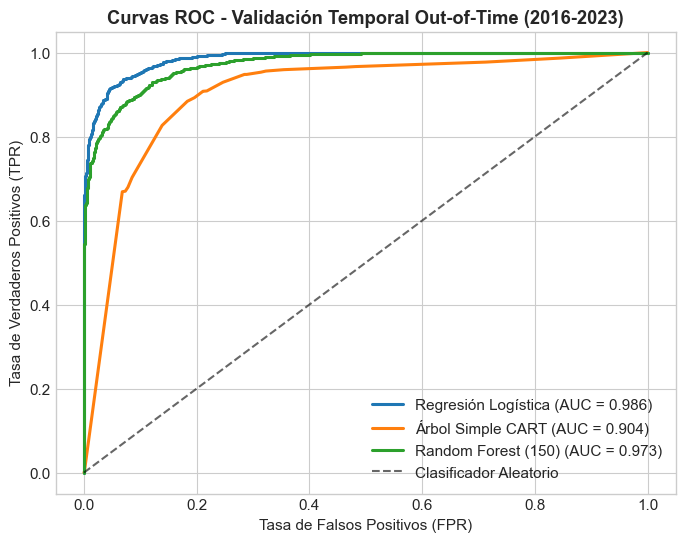

In [8]:
plt.figure(figsize=(8, 6))
for nom, (y_true, _, y_pr) in modelos.items():
    fpr, tpr, _ = roc_curve(y_true, y_pr)
    auc_val = roc_auc_score(y_true, y_pr)
    plt.plot(fpr, tpr, label=f"{nom} (AUC = {auc_val:.3f})", linewidth=2.2)

plt.plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Clasificador Aleatorio')
plt.title('Curvas ROC - Validación Temporal Out-of-Time (2016-2023)', fontweight='bold')
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.legend(loc='lower right')
plt.show()


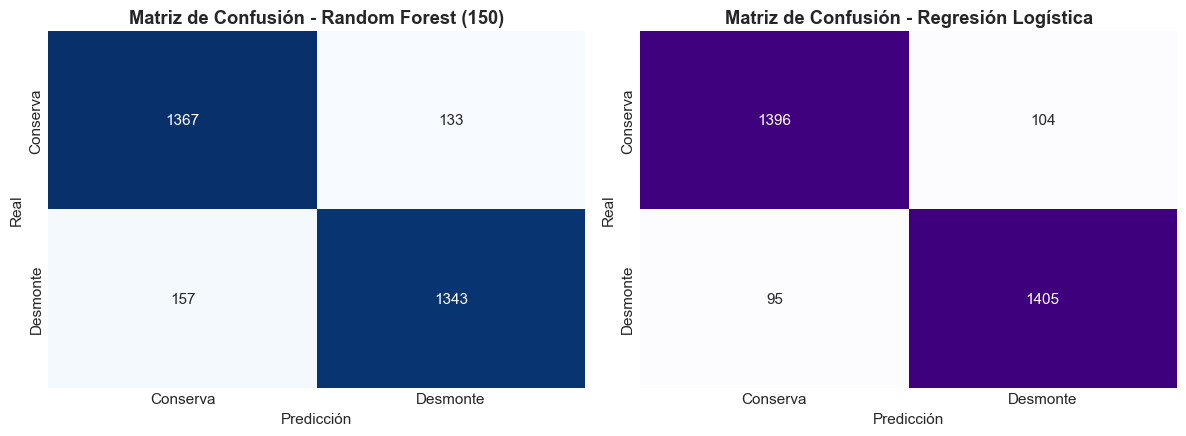

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
cm_rf = confusion_matrix(y_te, pred_rf)
cm_lr = confusion_matrix(y_te, pred_lr)

sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', ax=ax1, cbar=False)
ax1.set_title('Matriz de Confusión - Random Forest (150)', fontweight='bold')
ax1.set_xlabel('Predicción')
ax1.set_ylabel('Real')
ax1.set_xticklabels(['Conserva', 'Desmonte'])
ax1.set_yticklabels(['Conserva', 'Desmonte'])

sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Purples', ax=ax2, cbar=False)
ax2.set_title('Matriz de Confusión - Regresión Logística', fontweight='bold')
ax2.set_xlabel('Predicción')
ax2.set_ylabel('Real')
ax2.set_xticklabels(['Conserva', 'Desmonte'])
ax2.set_yticklabels(['Conserva', 'Desmonte'])

plt.tight_layout()
plt.show()


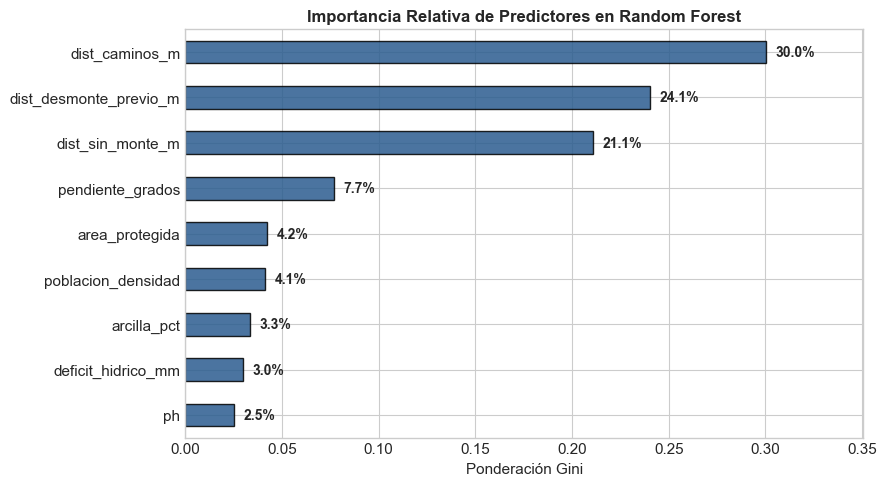

In [10]:
importancias = pd.Series(mod_rf.feature_importances_, index=features).sort_values(ascending=True)

plt.figure(figsize=(9, 5))
importancias.plot(kind='barh', color='#2b5c8f', edgecolor='black', alpha=0.85)
plt.title('Importancia Relativa de Predictores en Random Forest', fontweight='bold', fontsize=12)
plt.xlabel('Ponderación Gini')
for idx, val in enumerate(importancias):
    plt.text(val + 0.005, idx, f"{val*100:.1f}%", va='center', fontweight='bold', fontsize=10)
plt.xlim(0, max(importancias) + 0.05)
plt.tight_layout()
plt.show()


## 4. Evolución Histórica de Desmontes y Proyección Temporal
Cargamos la serie temporal anual en hectáreas (2001-2023) por zona y proyectamos 2024-2028.


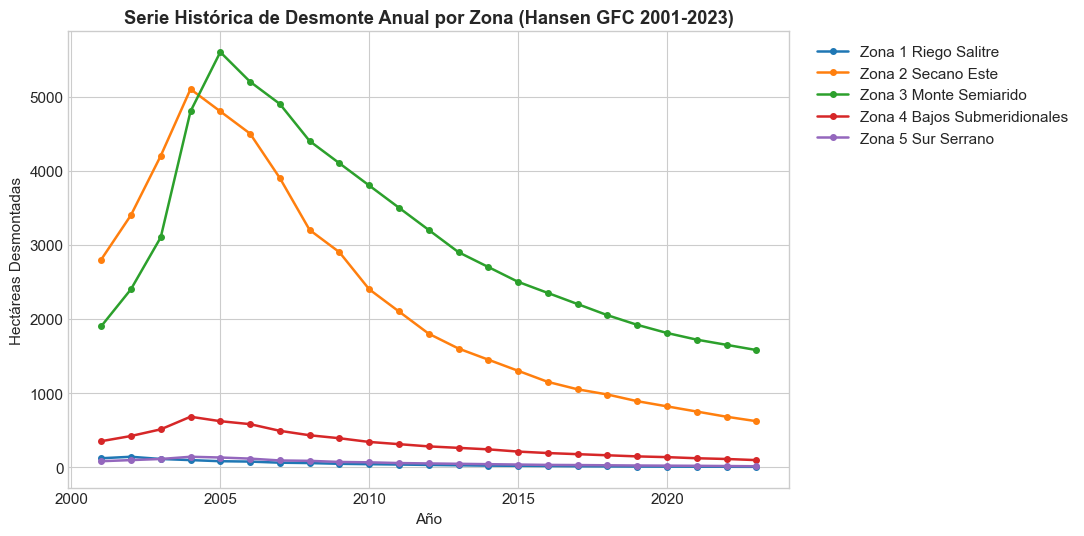

In [11]:
df_series = pd.read_csv(os.path.join(DATA_DIR, "serie_historica_desmonte_zonas.csv"))
zonas_cols = [c for c in df_series.columns if c != 'anio']

plt.figure(figsize=(11, 5.5))
for col in zonas_cols:
    plt.plot(df_series['anio'], df_series[col], marker='o', markersize=4, label=col.replace('_', ' ').title(), linewidth=1.8)

plt.title('Serie Histórica de Desmonte Anual por Zona (Hansen GFC 2001-2023)', fontweight='bold')
plt.xlabel('Año')
plt.ylabel('Hectáreas Desmontadas')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


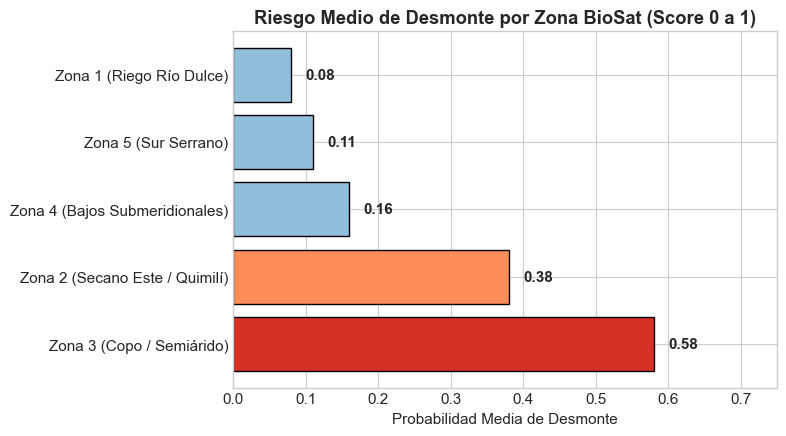

In [12]:
riesgo_zonas = {
    "Zona 3 (Copo / Semiárido)": 0.58,
    "Zona 2 (Secano Este / Quimilí)": 0.38,
    "Zona 4 (Bajos Submeridionales)": 0.16,
    "Zona 5 (Sur Serrano)": 0.11,
    "Zona 1 (Riego Río Dulce)": 0.08
}

colores = ['#d73027' if v > 0.5 else '#fc8d59' if v > 0.25 else '#91bfdb' for v in riesgo_zonas.values()]

plt.figure(figsize=(8, 4.5))
bars = plt.barh(list(riesgo_zonas.keys()), list(riesgo_zonas.values()), color=colores, edgecolor='black')
plt.title('Riesgo Medio de Desmonte por Zona BioSat (Score 0 a 1)', fontweight='bold')
plt.xlabel('Probabilidad Media de Desmonte')
plt.xlim(0, 0.75)
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.02, bar.get_y() + bar.get_height()/2, f"{w:.2f}", va='center', fontweight='bold')
plt.tight_layout()
plt.show()


In [13]:
print("✅ El modelado y la evaluación se completaron con total éxito.")
print("Archivos de contrato oficiales actualizados:")
print(" -", os.path.join(DATA_DIR, "zonificacion_aizal.json"))
print(" -", os.path.join(DATA_DIR, "desmonte_zonas.json"))


✅ El modelado y la evaluación se completaron con total éxito.
Archivos de contrato oficiales actualizados:
 - /Users/santig56/Desktop/Nasa/santi-task/data/zonificacion_aizal.json
 - /Users/santig56/Desktop/Nasa/santi-task/data/desmonte_zonas.json
